# Modelo Make-or-Buy Multiestágio

## 1. Introdução

### 1.1 O Problema
* **Objetivo:** Determinar o custo mínimo para obter demanda específica de itens alvo combinando estoque inicial, custos de produção interna e aquisição de componentes no mercado externo.
* **Estrutura em Grafo:** O sistema é modelado como um **Grafo Direcionado com Pesos**:
  * **Vértices (nós):** representam os itens, cada um com estoque, preço de compra e custo de produção.
  * **Arcos direcionados:** representam as receitas para produção de itens.
  * **Pesos:** indicam as proporções necessárias para produzir o item seguinte.

### 1.2 Aplicações Atuais
* **Indústria Petroquímica:** Malhas de refino e craqueamento catalítico com recirculação contínua de frações não convertidas.
* **Indústria Farmacêutica:** Síntese de compostos em lote (*batch*) com recuperação e reaproveitamento de reagentes residuais.
* **Engenharia Química e Processos:** Planejamento de produção integrada em plantas com múltiplos estágios de reação.


* **Planejamento de redes de processos químicos:** decidir o que produzir, comprar e expandir ao longo de uma cadeia é um uso clássico de programação matemática (Sahinidis et al., 1989).
* **Planejamento de necessidades de materiais (MRP):** calcular quanto de cada componente é preciso para atender um pedido final, etapa por etapa, é o mesmo cálculo de consumo por receita do nosso modelo (Orlicky, 1975).

### 1.3 Breve Histórico
* **Fazer ou comprar:** a decisão sobre o que a empresa produz internamente e o que adquire no mercado é discutida em economia desde Coase (1937), ao explicar a fronteira da firma.
* **Programação linear:** Kantorovich formulou problemas de planejamento da produção como otimização linear em 1939 (Kantorovich, 1960, tradução), e Dantzig criou o método simplex no fim da década de 1940 (Dantzig, 1963).
* **Hoje:** solvers como o HiGHS (Huangfu e Hall, 2018), acessível pelo SciPy (Virtanen et al., 2020), resolvem PLs deste tipo, e é o que usamos na seção 3.

## 2. Modelo Matemático

O problema de otimização é formulado como um modelo de **Programação Linear (PL)** sobre um grafo direcionado $G = (V, A)$, onde os vértices representam os itens e as arestas indicam as relações de dependência.

---
### 2.1 Conjuntos e Parâmetros
* **$V$:** Conjunto de todos os produtos (nós do grafo).
* **$A \subseteq V \times V$:** Conjunto de arestas direcionadas $(i, j)$, indicando que o item $i$ é utilizado como insumo na produção do item $j$.
* **$d_i \ge 0$:** Demanda externa do item $i \in V$ (em kg ou toneladas). Vale $d_i = 0$ para itens que não são produtos finais.
* **$E_i \ge 0$:** Estoque inicial disponível do item $i \in V$.
* **$C^{\text{compra}}_i$:** Custo unitário de aquisição externa do item $i \in V$.
* **$C^{\text{prod}}_i$:** Custo unitário operacional de produção interna do item $i \in V$.
* **$r_{ij}$:** Coeficiente técnico (peso do arco $(i,j) \in A$), representando a quantidade do insumo $i$ consumida na produção de $1$ unidade do item $j$. Não há laços: $(i,i) \notin A$.
* **$K^{\text{compra}}_i, K^{\text{prod}}_i \in [0, \infty]$:** Capacidades máximas de compra e de produção do item $i$ por período. O valor $\infty$ significa sem limite, que é o caso padrão.

---

### 2.2 Variáveis de Decisão
Para cada produto $i \in V$, definimos três variáveis contínuas e não-negativas:
* **$x_i \ge 0$:** Quantidade do item $i$ comprada externamente.
* **$y_i \ge 0$:** Quantidade do item $i$ produzida internamente.
* **$s_i \ge 0$:** Quantidade do estoque inicial $E_i$ efetivamente utilizada.

---

### 2.3 Função Objetivo
Minimizar o custo total de aquisição externa e produção interna de toda a cadeia:

$$\min Z = \sum_{i \in V} \left( C^{\text{compra}}_i \cdot x_i + C^{\text{prod}}_i \cdot y_i \right)$$

---

### 2.4 Restrições

**1. Balanço de Massa (Conservação de Fluxo nos Nós):**
Para cada produto $i \in V$, o total obtido (via estoque utilizado, compra externa e produção interna) deve ser suficiente para suprir a demanda externa e o consumo interno exigido pela produção de todos os compostos $j$ que dependem de $i$:

$$s_i + x_i + y_i \ge \sum_{j : (i,j) \in A} r_{ij} \cdot y_j + d_i, \quad \forall i \in V$$

**2. Limite de Disponibilidade de Estoque:**
A quantidade utilizada do estoque não pode ultrapassar o volume inicial armazenado:

$$s_i \le E_i, \quad \forall i \in V$$

**3. Capacidades de Compra e de Produção:**
Quando existem, limitam o que pode ser comprado e produzido por período:

$$x_i \le K^{\text{compra}}_i, \quad y_i \le K^{\text{prod}}_i, \quad \forall i \in V$$

**4. Não-Negatividade:**

$$x_i, y_i, s_i \ge 0, \quad \forall i \in V$$

---
### 2.5 Hipóteses e Aproximações
* **Linearidade:** custos unitários constantes e coeficientes $r_{ij}$ fixos (sem economia de escala, sem descontos por volume).
* **Capacidades fixas e opcionais:** cada item pode ter um teto de compra e um de produção, sem custo para ampliá-lo. Sem teto, a compra e a produção são ilimitadas.
* **Rendimento unitário:** cada unidade de $y_j$ gera exatamente $1$ unidade de $j$. Perdas e ganhos estequiométricos não são modelados.

---
### 2.6 Viabilidade e Limitação do Objetivo

* **Viabilidade:** se nenhum item tem capacidade de compra finita, a solução $x_i = d_i$, $y_i = 0$, $s_i = 0$ satisfaz todas as restrições, e o modelo é sempre viável. Com capacidades finitas, ele pode ficar **inviável**: se o que dá para comprar, produzir e tirar do estoque não cobre a demanda, não existe plano.
* **Objetivo limitado:** como $C^{\text{compra}}_i \ge 0$ e $C^{\text{prod}}_i \ge 0$ e as variáveis são não-negativas, vale $Z \ge 0$ para toda solução viável. Um PL viável e limitado inferiormente tem solução ótima finita. As capacidades não mudam isso, então o caso ilimitado nunca ocorre neste modelo.
* **Custos nulos:** os custos podem ser zero (o código aceita). O ótimo continua existindo, mas pode deixar de ser único, e um ciclo de custo zero admite infinitas soluções de mesmo valor.

## 3. Solução

Resolvemos primeiro uma instância pequena, em que dá para conferir o resultado à mão, e usamos os gráficos para entender o comportamento do modelo e da função objetivo. O modelo está em `src/engine.py` (classe `MakeOrBuyModel`, que monta o PL e o resolve com o HiGHS via `scipy.optimize.linprog`) e os gráficos em `src/plots.py`.

### 3.1 Instância de exemplo

Uma cadeia petroquímica com 5 itens. O cliente pede três produtos: solvente (20), aditivo (40) e polímero (100). O etileno é a única matéria-prima com estoque inicial (60).

| Item | Estoque $E_i$ | Demanda $d_i$ | Compra $C^{\text{compra}}_i$ | Produção $C^{\text{prod}}_i$ |
|---|---|---|---|---|
| etileno | 60 | 0 | 2,0 | 2,5 |
| propileno | 0 | 0 | 3,0 | 1,5 |
| solvente | 0 | 20 | 2,5 | 1,0 |
| aditivo | 0 | 40 | 2,5 | 1,0 |
| polímero | 0 | 100 | 12,0 | 3,0 |

Receitas $r_{ij}$ (insumo $\to$ produto): etileno $\to$ solvente (0,6), propileno $\to$ solvente (0,5), etileno $\to$ aditivo (0,3), propileno $\to$ aditivo (0,8), solvente $\to$ polímero (0,7) e etileno $\to$ polímero (0,4). A receita consome todos os insumos juntos.

In [99]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [100]:
from copy import deepcopy

from src.legacy.engine import InfeasibleError, MakeOrBuyModel
from src.legacy.plots import (
    plot_cost_breakdown,
    plot_demand_sensitivity,
    plot_feasible_region,
    plot_graph,
    plot_sensitivity,
)

modelo = MakeOrBuyModel()
modelo.add_item("etileno", inventory=60, purchase_cost=2.0, production_cost=2.5)
modelo.add_item("propileno", purchase_cost=3.0, production_cost=1.5)
modelo.add_item("solvente", demand=20, purchase_cost=2.5, production_cost=1.0)
modelo.add_item("aditivo", demand=40, purchase_cost=2.5, production_cost=1.0)
modelo.add_item("polimero", demand=100, purchase_cost=12.0, production_cost=3.0)

# add_recipe(insumo, produto, quantidade de insumo por unidade de produto)
modelo.add_recipe("etileno", "solvente", 0.6)
modelo.add_recipe("propileno", "solvente", 0.5)
modelo.add_recipe("etileno", "aditivo", 0.3)
modelo.add_recipe("propileno", "aditivo", 0.8)
modelo.add_recipe("solvente", "polimero", 0.7)
modelo.add_recipe("etileno", "polimero", 0.4)

### 3.2 Resolvendo o PL

`solve()` monta as matrizes do problema $\min c^\top v$ sujeito a $Av \le b$ e $0 \le v \le u$, onde o vetor $v$ reúne $(x_i, y_i, s_i)$ de cada item, e devolve as quantidades ótimas.

In [101]:
solucao = modelo.solve()

print(f"Custo ótimo: {solucao.total_cost:.2f}\n")
print(f"{'item':<10}{'compra':>10}{'produção':>10}{'estoque':>10}")
for i, nome in enumerate(modelo.item_names):
    print(
        f"{nome:<10}{solucao.purchases[i]:>10.2f}"
        f"{abs(solucao.production[i]):>10.2f}{solucao.inventory_used[i]:>10.2f}"
    )

Custo ótimo: 600.00

item          compra  produção   estoque
etileno         0.00      0.00     60.00
propileno       0.00     16.67      0.00
solvente       56.67     33.33      0.00
aditivo        40.00      0.00      0.00
polimero        0.00    100.00      0.00


**Conferência.** Recalculamos o custo a partir das quantidades e a folga de cada restrição de balanço, $s_i + x_i + y_i - \sum_j r_{ij} y_j - d_i \ge 0$. Folga zero significa que a restrição está ativa, ou seja, não se produz nem se compra além do necessário.

In [102]:
custo = (
    solucao.purchases @ modelo.purchase_costs
    + solucao.production @ modelo.production_costs
)
print(f"Custo recalculado: {custo:.2f}\n")

consumo = [0.0] * len(modelo.item_names)  # consumo interno de cada insumo
for (insumo, produto), r in modelo.recipes.items():
    consumo[insumo] += r * solucao.production[produto]

for i, nome in enumerate(modelo.item_names):
    oferta = solucao.purchases[i] + solucao.production[i] + solucao.inventory_used[i]
    folga = oferta - consumo[i] - modelo.demands[i]
    print(f"{nome:<10} folga do balanço = {folga:8.4f}")

Custo recalculado: 600.00

etileno    folga do balanço =   0.0000
propileno  folga do balanço =   0.0000
solvente   folga do balanço =   0.0000
aditivo    folga do balanço =   0.0000
polimero   folga do balanço =   0.0000


O plano ótimo usa as três fontes, mas cada item usa só as que lhe convêm:

| Item | Estoque | Compra | Produção | Observação |
|---|---|---|---|---|
| etileno | 60 | 0 | 0 | o estoque cobre todo o consumo |
| propileno | 0 | 0 | 16,7 | usado só para produzir solvente |
| solvente | 0 | 56,7 | 33,3 | demanda total de 90; o etileno do estoque só dá para produzir 33,3 |
| aditivo | 0 | 40 | 0 | sem estoque, comprar (2,5) sai mais barato que produzir (2,8) |
| polímero | 0 | 0 | 100 | produzir (5,55) sai bem mais barato que comprar (12,0) |

O solvente é o único item dividido. O estoque de etileno é limitado, então só parte do solvente pode ser produzida a custo baixo. O resto é comprado.

### Por que esse plano é ótimo

O estoque de etileno é o recurso escasso. Etileno gratuito deixa a produção mais barata, mas o estoque não cobre todos os usos. Quanto vale **uma unidade de estoque de etileno** em cada uso?

| Uso do estoque | Economia | Por unidade de etileno |
|---|---|---|
| no polímero (0,4 por unidade) | evita comprar etileno a 2,0 | $2{,}0$ |
| no solvente (0,6 por unidade) | produzir passa a custar $1{,}0 + 0{,}75 = 1{,}75$, contra 2,5 de comprar: economia de 0,75 | $0{,}75 / 0{,}6 = 1{,}25$ |
| no aditivo (0,3 por unidade) | produzir passa a custar $1{,}0 + 1{,}2 = 2{,}2$, contra 2,5 de comprar: economia de 0,3 | $0{,}3 / 0{,}3 = 1{,}0$ |
O estoque vai primeiro para o uso que mais rende (polímero, depois solvente, depois aditivo) até acabar. Os 60 de etileno se dividem em 40 para o polímero e 20 para o solvente, e o aditivo fica sem estoque. O solver faz essa disputa para todos os itens ao mesmo tempo.

### 3.3 Plano ótimo no grafo

Cada nó mostra as quantidades usadas de compra, produção e estoque. A cor indica a combinação de fontes do item: o solvente aparece como "compra + produção", o aditivo como "compra", o etileno como "estoque" e o propileno e o polímero como "produção". O número em cada arco é o coeficiente $r_{ij}$.

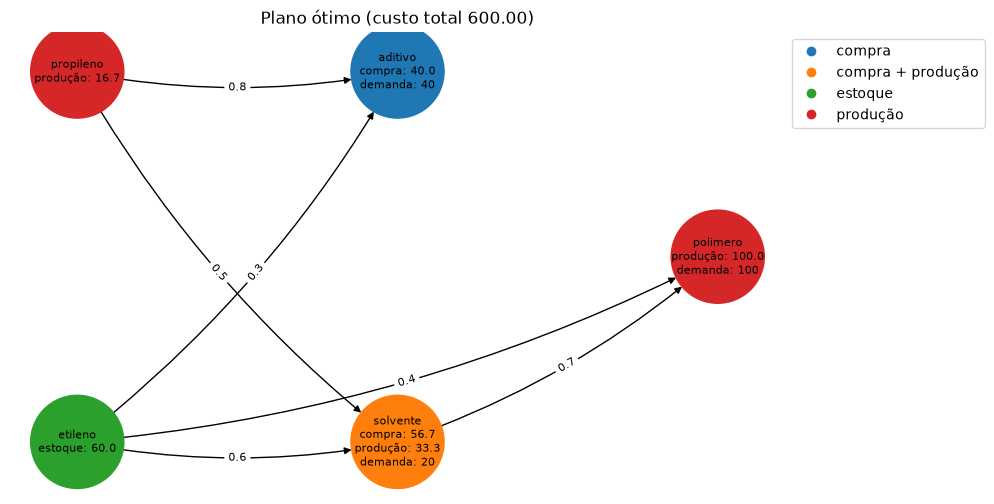

In [103]:
plot_graph(modelo, solucao)

### 3.4 De onde vem o custo

Barras empilhadas com o custo de compra e de produção de cada item no ótimo. O polímero pesa mais (300), seguido do solvente (141,67 de compra mais 33,33 de produção), do aditivo (100) e do propileno (25). O etileno não tem barra porque vem do estoque, que tem custo zero.

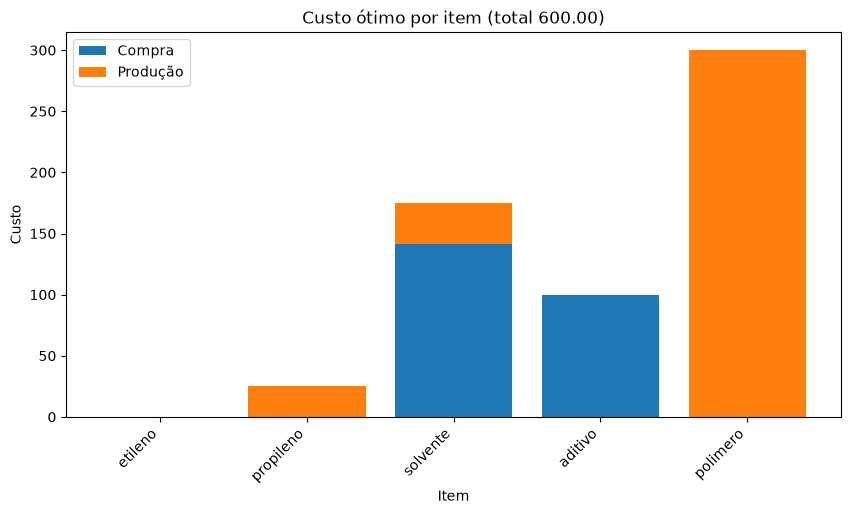

In [104]:
plot_cost_breakdown(modelo, solucao)

### 3.5 Solução gráfica: região viável e curvas de nível

O modelo completo tem 15 variáveis, então não cabe em um gráfico de duas dimensões. Para ver a geometria do PL, fixamos todas as variáveis no valor ótimo, menos duas, e analisamos o problema só com elas. O ótimo desse problema reduzido é o mesmo do modelo completo.

As duas variáveis são a compra $x$ e a produção $y$ de solvente, o único item que usa as duas fontes. Elas têm duas restrições:
* **Demanda:** o solvente pedido (20 do cliente mais 70 do polímero) precisa ser coberto, então $x + y \ge 90$.
* **Estoque de etileno:** o polímero usa 40 dos 60 de estoque, e sobram 20 para o solvente. Cada unidade produzida usa $0{,}6$ de etileno, então $0{,}6\,y \le 20$, ou seja, $y \le 33{,}3$.

O custo dessas duas variáveis é $2{,}5x + 1{,}0y$.

Como ler o gráfico:
* **Região azul:** os pares $(x, y)$ que respeitam as restrições. Ela fica à direita da reta $x + y = 90$, entre $y = 0$ e $y = 33{,}3$. Fica aberta para a direita, porque comprar mais que o necessário é permitido, mas custa mais.
* **Linhas alaranjadas:** as curvas de nível de $2{,}5x + y$. São retas paralelas, e todos os pontos de uma mesma reta têm o mesmo custo. O custo cresce para a direita e para cima.
* **Estrela:** o ótimo, que é o ponto da região azul com menor custo. Fica no vértice $(x, y) = (56{,}7;\ 33{,}3)$, onde as duas restrições se encontram. Comprar custa mais que produzir, então o plano produz o máximo que o estoque permite e compra o resto.

Esse ótimo fica num **canto** da região, como na aula sobre geometria de PL.

Os valores nas curvas são só o custo dessas duas variáveis. As demais estão fixas e não entram.

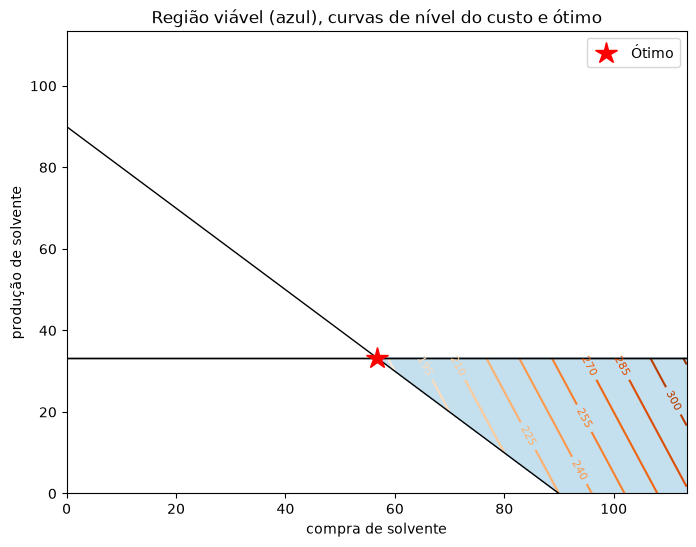

In [105]:
plot_feasible_region(
    modelo,
    ("compra", "solvente"),
    ("produção", "solvente"),
    solucao,
)

### 3.6 Comportamento da função objetivo

Variamos a demanda de polímero e resolvemos o PL de novo a cada valor. O resultado é o custo ótimo $Z^*(d)$. Pela teoria de PL, $Z^*$ é **convexa e linear por partes** em $d$. A inclinação muda quando muda o uso do estoque de etileno.

Cada unidade a mais de polímero consome $0{,}4$ de etileno direto e $0{,}7 \cdot 0{,}6 = 0{,}42$ via solvente, se o solvente for produzido. O estoque (60) atende primeiro o solvente (20) e o aditivo (40) pedidos pelo cliente. O que sobra vai para o polímero até acabar. Isso gera três pontos de quebra:

| Faixa de $d$ | O que acontece | Custo de uma unidade a mais |
|---|---|---|
| até 43,9 | o estoque cobre tudo (24 unidades para solvente e aditivo, $0{,}82$ por polímero) | $3{,}0 + 0{,}7 \cdot 1{,}75 = 4{,}225$ |
| 43,9 a 58,5 | o estoque acaba. O aditivo, que rende menos (1,0 por unidade de etileno), passa de produzido para comprado | $5{,}045$ |
| 58,5 a 150 | o solvente passa a ser comprado aos poucos, e o estoque vai todo para o etileno direto do polímero | $3{,}0 + 0{,}7 \cdot 2{,}5 + 0{,}4 \cdot 1{,}25 = 5{,}25$ |
| acima de 150 | o estoque inteiro (60) já é usado no polímero ($0{,}4 \cdot 150$). Todo etileno extra é comprado | $3{,}0 + 0{,}7 \cdot 2{,}5 + 0{,}4 \cdot 2{,}0 = 5{,}55$ |

A inclinação só cresce, então a curva é convexa. Os pontos de quebra vêm de contas simples: $43{,}9 = (60 - 24) / 0{,}82$, $58{,}5 = 43{,}9 + 12 / 0{,}82$ e $150 = 60 / 0{,}4$.

In [106]:
def custo_otimo(demanda):
    variante = deepcopy(modelo)  # não altera o modelo original
    variante.set_demand("polimero", demanda)
    return variante.solve().total_cost


def inclinacao(a, b):
    return (custo_otimo(b) - custo_otimo(a)) / (b - a)


print("Pontos de quebra previstos:",
      f"{(60 - 24) / 0.82:.1f}, {(60 - 24) / 0.82 + 12 / 0.82:.1f} e {60 / 0.4:.0f}")
print(f"Custo marginal, d de 0 a 10:    {inclinacao(0, 10):.3f}")
print(f"Custo marginal, d de 46 a 56:   {inclinacao(46, 56):.3f}")
print(f"Custo marginal, d de 60 a 100:  {inclinacao(60, 100):.3f}")
print(f"Custo marginal, d de 160 a 170: {inclinacao(160, 170):.3f}")

Pontos de quebra previstos: 43.9, 58.5 e 150
Custo marginal, d de 0 a 10:    4.225
Custo marginal, d de 46 a 56:   5.045
Custo marginal, d de 60 a 100:  5.250
Custo marginal, d de 160 a 170: 5.550


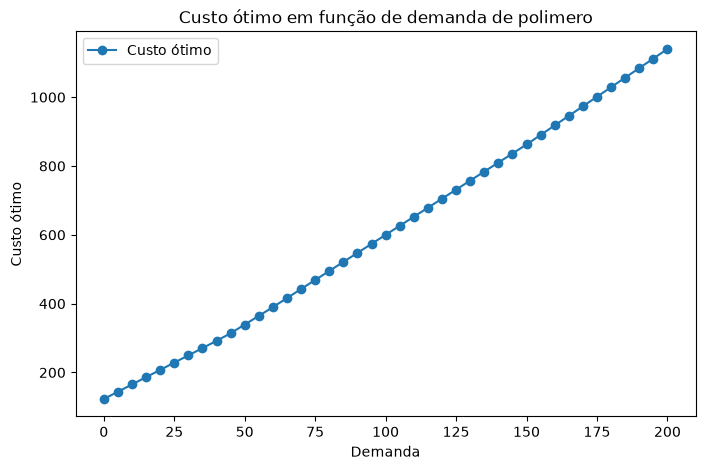

In [107]:
plot_demand_sensitivity(modelo, "polimero", range(0, 201, 5))

Em cada faixa, o custo de uma unidade a mais é o custo de produzir o polímero mais o custo dos insumos. O custo dos insumos depende de quanto o estoque ainda rende. Por isso a inclinação sobe em degraus, de 4,225 (estoque sobrando) até 5,55 (todo o etileno comprado).

#### Outros parâmetros

`plot_sensitivity` faz o mesmo para qualquer parâmetro de um item: `"demanda"`, `"estoque"`, `"custo de compra"`, `"custo de produção"`, `"capacidade de compra"` ou `"capacidade de produção"`.

**Estoque de etileno.** A curva cai com três inclinações, uma por uso do estoque, do que mais rende ao que menos rende (seção 3.2): $-2{,}0$ até 40 (polímero), $-1{,}25$ até 94 (solvente, $40 + 0{,}6 \cdot 90$) e $-1{,}0$ até 106 (aditivo, $94 + 0{,}3 \cdot 40$). Acima de 106 o estoque cobre todo o etileno e o custo fica constante em $545{,}5$. As inclinações ficam menos negativas, então a curva é **convexa**.

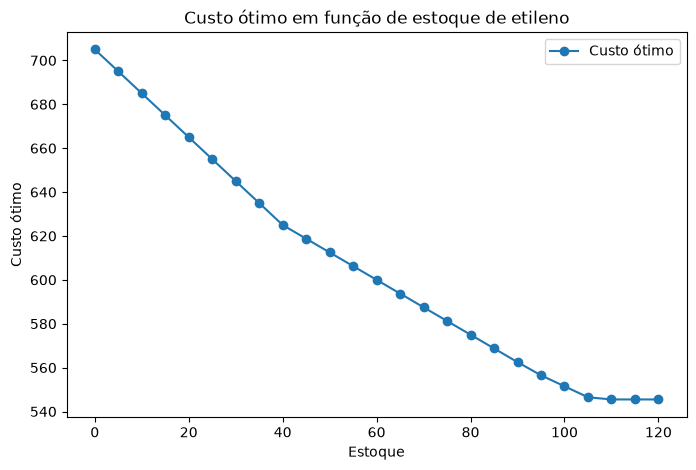

In [108]:
plot_sensitivity(modelo, "estoque", "etileno", range(0, 121, 5))

**Preço de compra do solvente.** A curva é **côncava**, porque o ótimo é o mínimo de funções lineares do preço. A inclinação é a quantidade de solvente comprada, e ela cai a cada ponto de quebra:

| Preço | Inclinação | O que muda |
|---|---|---|
| até 1,75 | 90 | compra todo o solvente (90 unidades) |
| 1,75 a 2,35 | 76,7 | produzir com etileno do estoque ($1{,}0 + 0{,}75 = 1{,}75$) passa a valer a pena |
| 2,35 a 2,95 | 56,7 | o estoque do aditivo passa para o solvente (plano da seção 3.2, com preço 2,5) |
| acima de 2,95 | 0 | produzir mesmo comprando todos os insumos ($1{,}0 + 1{,}2 + 0{,}75 = 2{,}95$) já sai mais barato, e o custo fica em $625{,}5$ |

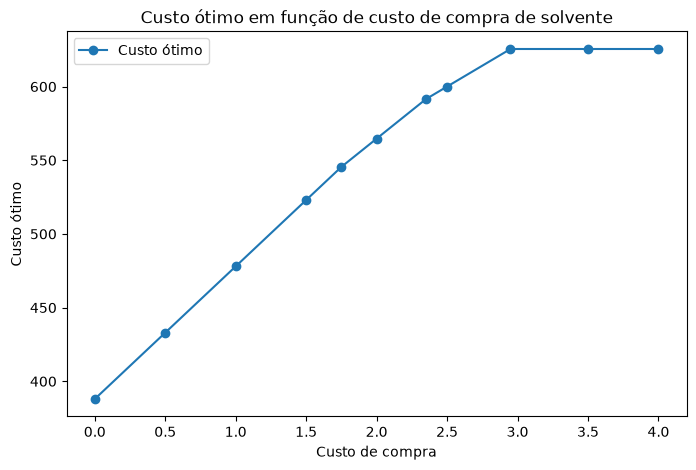

In [109]:
plot_sensitivity(modelo, "custo de compra", "solvente", [0, 0.5, 1, 1.5, 1.75, 2, 2.35, 2.5, 2.95, 3.5, 4])

### 3.7 Capacidades de compra e de produção

Até aqui compra e produção eram ilimitadas. Na prática, uma máquina produz até um limite por período e um fornecedor entrega até um certo volume. Cada item pode ter esses limites: `purchase_capacity` e `production_capacity` em `add_item`, ou `set_purchase_capacity` e `set_production_capacity` depois. O valor `None` significa sem limite. No PL, eles entram como $x_i \le K^{\text{compra}}_i$ e $y_i \le K^{\text{prod}}_i$ (seção 2.4).

**Exemplo.** Limitamos a produção de polímero a 60 unidades. O cliente pede 100, então as 40 restantes são compradas a 12,0 cada, bem acima do custo de produzir.

In [110]:
limitado = deepcopy(modelo)
limitado.set_production_capacity("polimero", 60)
sol_limitado = limitado.solve()

print(f"Custo sem limite: {solucao.total_cost:.2f}   com capacidade 60: {sol_limitado.total_cost:.2f}\n")
print(f"{'item':<10}{'compra antes':>14}{'compra depois':>15}{'prod. antes':>13}{'prod. depois':>14}")
for i, nome in enumerate(modelo.item_names):
    print(
        f"{nome:<10}{solucao.purchases[i]:>14.1f}{sol_limitado.purchases[i]:>15.1f}"
        f"{abs(solucao.production[i]):>13.1f}{abs(sol_limitado.production[i]):>14.1f}"
    )

Custo sem limite: 600.00   com capacidade 60: 870.00

item        compra antes  compra depois  prod. antes  prod. depois
etileno              0.0            0.0          0.0           0.0
propileno            0.0            0.0         16.7          30.0
solvente            56.7            2.0         33.3          60.0
aditivo             40.0           40.0          0.0           0.0
polimero             0.0           40.0        100.0          60.0


O custo sobe de 600 para **870**. A mudança em um único item se espalha pela cadeia:
* **Polímero:** produz 60 e compra 40 (antes não comprava nada).
* **Solvente:** com menos polímero, a demanda cai de 90 para $20 + 0{,}7 \cdot 60 = 62$. O plano produz quase tudo (60 de 62).
* **Etileno do estoque:** o polímero usa menos ($0{,}4 \cdot 60 = 24$), e as 36 unidades que sobram vão para o solvente ($0{,}6 \cdot 60$). Por isso o solvente quase não é mais comprado.
* **Propileno:** sobe de 16,7 para 30 ($0{,}5 \cdot 60$), porque o solvente produzido aumentou.

A capacidade também aparece na solução gráfica. No gráfico de compra × produção de polímero, a reta horizontal $y = 60$ é o limite de capacidade. Os insumos fixados no ótimo impõem o mesmo limite, então a linha tracejada da capacidade fica coberta por essa reta. O ótimo está no vértice $(x, y) = (40, 60)$, onde a demanda ($x + y = 100$) encontra a capacidade. O gráfico mostra só as duas variáveis do polímero, com custo $12x + 3y$.

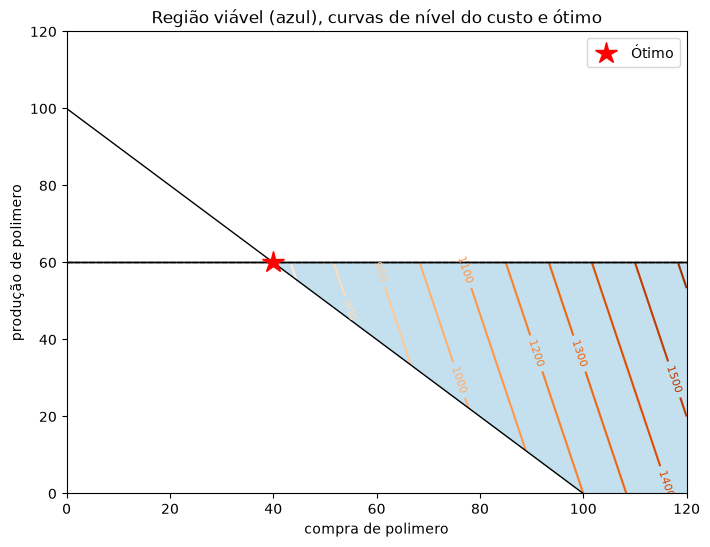

In [111]:
plot_feasible_region(
    limitado,
    ("compra", "polimero"),
    ("produção", "polimero"),
    sol_limitado,
)

**Quanto vale uma unidade de capacidade?** Variamos a capacidade de produção do polímero de 0 a 120. O custo ótimo cai e fica constante a partir de 100, quando a demanda já está coberta. Cada unidade de capacidade a mais troca uma compra de polímero (12,0) por uma produção. O ganho é 12 menos o custo marginal de produzir, que é a inclinação da seção 3.6:

| Capacidade | Custo marginal de produzir (seção 3.6) | Inclinação da curva |
|---|---|---|
| até 43,9 | 4,225 | $4{,}225 - 12 = -7{,}775$ |
| 43,9 a 58,5 | 5,045 | $-6{,}955$ |
| 58,5 a 100 | 5,25 | $-6{,}75$ |
| acima de 100 | (sem ganho) | $0$ |

As inclinações crescem até zero, então a curva é **convexa**.

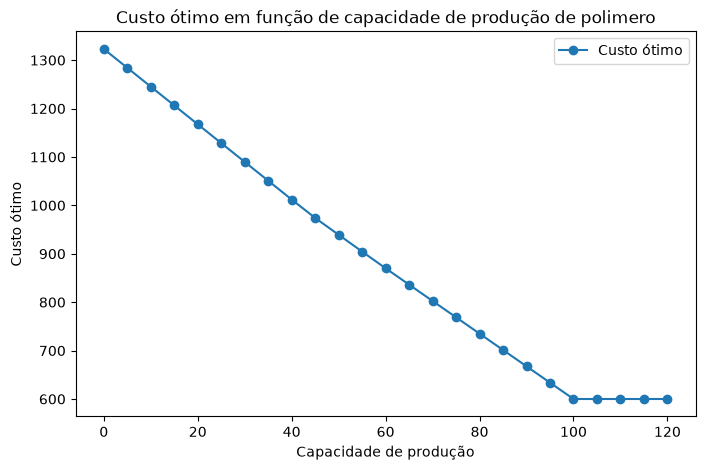

In [112]:
plot_sensitivity(modelo, "capacidade de produção", "polimero", range(0, 121, 5))

**Modelo inviável.** Limites demais podem impedir qualquer plano. Com a compra de polímero limitada a 30, só dá para obter $60 + 30 = 90$ das 100 unidades pedidas. Nenhuma combinação de compra, produção e estoque atende o cliente, e o PL é **inviável**. O modelo sem capacidades nunca chegava a esse caso. O caso ilimitado continua impossível, porque os custos não são negativos (seção 2.6).

In [113]:
inviavel = deepcopy(limitado)
inviavel.set_purchase_capacity("polimero", 30)  # 60 produzidos + 30 comprados < 100 pedidos

try:
    inviavel.solve()
except InfeasibleError as erro:
    print("Modelo inviável:", erro)

Modelo inviável: No feasible plan: The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)


### 3.8 Generalização: instâncias sorteadas

Até aqui usamos uma instância escrita à mão. O mesmo modelo resolve qualquer cadeia de itens, então podemos **sortear** os dados de itens `p1, ..., p10`. O gerador `random_model` (em `src/instances.py`) sorteia:
* **Receitas:** o insumo $p_i$ entra na receita de $p_j$ com probabilidade 25%, e só se $i < j$, o que garante um grafo **sem ciclos**. Os $r_{ij}$ vêm de $U(0{,}2;\,1{,}5)$.
* **Demanda:** só os produtos finais (itens que não são insumo de ninguém) têm demanda, entre 20 e 100.
* **Estoque:** cada item tem 40% de chance de ter estoque, entre 5 e 50.
* **Capacidade de produção:** cada item tem 30% de chance de ter um limite, entre 30% e 90% da quantidade necessária se tudo fosse produzido. A compra segue ilimitada.
* **Custo de produção:** $U(0{,}5;\,5{,}0)$.
* **Custo de compra:** o custo de produzir o item do zero (a produção dele mais os insumos, também produzidos) vezes $U(0{,}6;\,1{,}8)$. Quando o fator fica abaixo de 1, comprar sai mais barato que produzir, e o ótimo **mistura compra e produção**.

Como a compra não tem limite e os custos não são negativos, toda instância sorteada é viável e tem ótimo finito (seção 2.6). O parâmetro `seed` torna o sorteio reprodutível.

In [114]:
from src.legacy.instances import random_model

sorteado = random_model(n_items=10, seed=1)

print(f"{'item':<5}{'estoque':>8}{'cap. prod.':>11}{'demanda':>9}{'compra':>8}{'produção':>10}  insumos")
for i, nome in enumerate(sorteado.item_names):
    insumos = ", ".join(
        f"{r:.2f}·{sorteado.item_names[k]}"
        for (k, j), r in sorteado.recipes.items() if j == i
    )
    capacidade = sorteado.production_capacities[i]
    print(
        f"{nome:<5}{sorteado.inventories[i]:>8.0f}"
        f"{'-' if capacidade is None else f'{capacidade:.1f}':>11}"
        f"{sorteado.demands[i]:>9.0f}"
        f"{sorteado.purchase_costs[i]:>8.2f}{sorteado.production_costs[i]:>10.2f}"
        f"  {insumos or '-'}"
    )

item  estoque cap. prod.  demanda  compra  produção  insumos
p1         30          -        0    4.49      4.09  -
p2         25          -        0   12.65      3.66  1.30·p1
p3          0       15.7        0    4.28      2.79  -
p4          7          -        0    2.70      2.27  -
p5          0          -        0   10.37      3.67  0.24·p2
p6          0          -        0   10.07      2.27  0.78·p2, 1.43·p4
p7          0          -       89   24.95      4.92  0.23·p1, 0.75·p5, 0.49·p6
p8          0          -       66   25.42      1.54  0.50·p3, 0.80·p4, 1.29·p6
p9          0          -        0   16.04      2.57  1.49·p2, 0.63·p4
p10         0       44.7       86    8.40      4.81  0.52·p9


In [115]:
sol = sorteado.solve()
print(f"Custo ótimo: {sol.total_cost:.2f}\n")
print(f"{'item':<5}{'compra':>9}{'produção':>10}{'estoque':>9}  no limite?")
for i, nome in enumerate(sorteado.item_names):
    capacidade = sorteado.production_capacities[i]
    no_limite = capacidade is not None and sol.production[i] >= capacidade - 1e-6
    print(
        f"{nome:<5}{sol.purchases[i]:>9.1f}{abs(sol.production[i]):>10.1f}"
        f"{sol.inventory_used[i]:>9.1f}  {'sim' if no_limite else ''}"
    )

Custo ótimo: 2956.82

item    compra  produção  estoque  no limite?
p1         0.0       0.0     30.0  
p2         0.0       7.3     25.0  
p3        17.3      15.7      0.0  sim
p4         0.0      75.7      7.0  
p5         0.0      66.8      0.0  
p6       107.8      20.9      0.0  
p7         0.0      89.0      0.0  
p8         0.0      66.0      0.0  
p9         0.0       0.0      0.0  
p10       86.0       0.0      0.0  


In [ ]:
plot_graph(sorteado, sol, figsize=(14, 8))

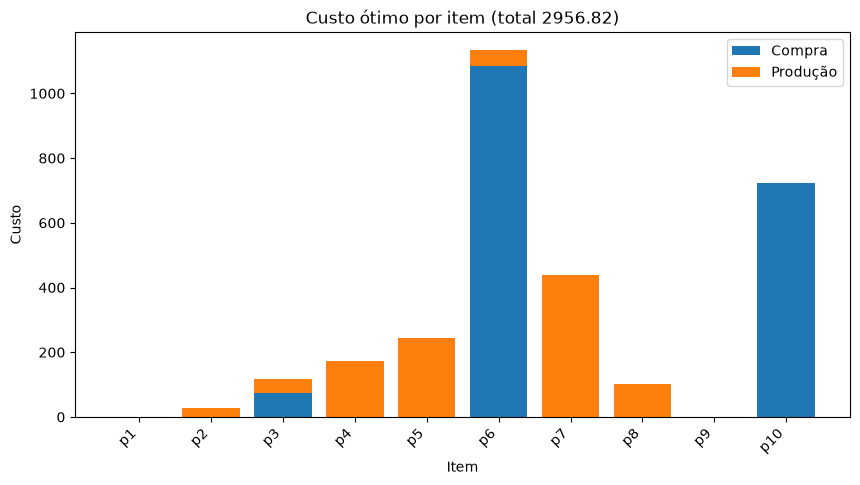

In [ ]:
plot_cost_breakdown(sorteado, sol)

A cor de cada nó mostra as fontes que o ótimo usa. O estoque é usado primeiro, por ser gratuito. Itens em que comprar custa menos que produzir (fator de compra abaixo de 1, ou insumos caros) aparecem como comprados, e os demais como produzidos. Na `seed` 1, o item p3 tem capacidade de 15,7 e usa tudo (coluna "no limite?"), então o resto da demanda dele (17,3) é comprado.

#### Várias seeds

Repetimos o sorteio com valores diferentes de `seed` para ver como o custo e a estratégia variam entre instâncias.

In [ ]:
print(f"{'seed':>8}{'custo ótimo':>14}{'itens comprados':>17}{'itens produzidos':>18}")
for seed in range(10):
    m = random_model(10, seed=seed)
    s = m.solve()
    print(
        f"{seed:>8}{s.total_cost:>14.2f}"
        f"{(s.purchases > 1e-9).sum():>17}{(s.production > 1e-9).sum():>18}"
    )

 semente   custo ótimo  itens comprados  itens produzidos
       0       2095.47                3                 9
       1       2956.82                3                 7
       2       1265.73                3                 2
       3       2515.14                5                 4
       4       1405.69                2                 7
       5        901.88                3                 6
       6        581.39                1                 7
       7       1767.10                4                 7
       8        470.77                2                 7
       9        867.77                2                 6


Em todas as seeds o PL tem solução, como previsto. O que muda é o custo e a divisão entre comprar e produzir.

## 4. Discussão

## 5. Referências